# 01 — Independent SAM–Vicon synchronization

**Goal:** Extract one arm-elevation reference from the matching Vicon C3D, then estimate **separate video-clock offsets for each camera** using SAM-based arm-sync CSVs. No knee/hip/ankle waveform fitting. All detected events are **candidates requiring visual review**, not accepted ground truth.

Run top-to-bottom from the repository root or `notebooks/`. The original joint-angle CSVs with `time_ms_aligned` should **not** be re-shifted.


In [43]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import ezc3d
from IPython.display import display, Image

ROOT = Path.cwd().resolve()
if not (ROOT / 'src').is_dir() and (ROOT.parent / 'src').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'src').is_dir():
    raise FileNotFoundError('Run Jupyter from markerless_sam/ or notebooks/')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.synchronization import synchronize

# Single source of configuration — change these for another trial.
SUBJECT = 'S11'
TRIAL = 'lunge_01'
SYNC_ARM = 'right'  # same physical arm in SAM and Vicon
if SYNC_ARM not in ("left", "right"):
    raise ValueError("SYNC_ARM must be left or right")
CAMERAS = ('cam0', 'cam1') #leave out cam2 for now, as it is unreliable
WINDOW_MS = 8000.0  # detection searches from start of EACH recording

if SYNC_ARM not in ('left', 'right'):
    raise ValueError('SYNC_ARM must be left or right')
DATA_DIR = ROOT / 'lunge_sam_out'
RESULTS_DIR = ROOT / 'results'
TRIAL_DIR = DATA_DIR / SUBJECT / TRIAL

# Current C3D naming: S9/lunge_01 corresponds to s9_lunge_0_1.c3d.
C3D_PATH = DATA_DIR / f'{SUBJECT.lower()}_lunge_0_1.c3d'
VICON_SYNC_PATH = TRIAL_DIR / 'vicon_sync.csv'
print('Repository:', ROOT)
print('C3D:', C3D_PATH, 'exists:', C3D_PATH.is_file())
print('SAM sync files:', [p.name for p in sorted(DATA_DIR.glob(f'{SUBJECT.lower()}_lunge_cam*_sam_sync.csv'))])


Repository: /Users/thomasjohnson/markerless/markerless_sam
C3D: /Users/thomasjohnson/markerless/markerless_sam/lunge_sam_out/s11_lunge_0_1.c3d exists: True
SAM sync files: ['s11_lunge_cam0_sam_sync.csv', 's11_lunge_cam1_sam_sync.csv', 's11_lunge_cam2_sam_sync.csv']


## 1. Export Vicon reference arm signals — once per trial

The Vicon wrist/hand displacement is projected onto trunk-up and normalized by torso length; it is a **sync proxy**, not an anatomical shoulder angle. Check actual marker names and C3D first-frame/time metadata. The same Vicon reference is reused across cameras.


In [44]:
if not C3D_PATH.is_file():
    candidates = sorted(DATA_DIR.rglob('*.c3d'))
    raise FileNotFoundError(f'{C3D_PATH} missing. Available: {[str(p.relative_to(DATA_DIR)) for p in candidates]}')

c3d = ezc3d.c3d(str(C3D_PATH))
labels = [str(label).strip() for label in c3d['parameters']['POINT']['LABELS']['value']]
points = c3d['data']['points']
fps = float(c3d['header']['points']['frame_rate'])
required = ('LCLAVLAT', 'RCLAVLAT', 'LHAND', 'RHAND', 'LASI', 'RASI')
missing = sorted(set(required) - set(labels))
if missing:
    raise KeyError(f'Missing markers {missing}; inspect labels: {labels}')

def marker(name):
    return np.asarray(points[:3, labels.index(name), :].T, dtype=float)

l_sh, r_sh = marker('LCLAVLAT'), marker('RCLAVLAT')
l_hand, r_hand = marker('LHAND'), marker('RHAND')
lasis, rasis = marker('LASI'), marker('RASI')
up_vector = (l_sh + r_sh - lasis - rasis) / 2.0
torso_length = np.linalg.norm(up_vector, axis=1)
valid_torso = np.isfinite(torso_length) & (torso_length > 1e-6)
up = np.full_like(up_vector, np.nan)
up[valid_torso] = up_vector[valid_torso] / torso_length[valid_torso, None]

def arm_raise(hand, shoulder):
    height = np.sum((hand - shoulder) * up, axis=1)
    return np.divide(height, torso_length, out=np.full_like(height, np.nan), where=valid_torso)

left_raise = arm_raise(l_hand, l_sh)
right_raise = arm_raise(r_hand, r_sh)

# Native sampling starts at the first stored frame. Check C3D first_frame
# and acquisition metadata if an external clock origin is needed.
vicon_sync = pd.DataFrame({
    'time_ms': np.arange(points.shape[2], dtype=float) * 1000.0 / fps,
    'left_arm_raise': left_raise,
    'right_arm_raise': right_raise,
})
VICON_SYNC_PATH.parent.mkdir(parents=True, exist_ok=True)
vicon_sync.to_csv(VICON_SYNC_PATH, index=False)
print('Saved:', VICON_SYNC_PATH, '| frames:', len(vicon_sync), '| rate:', fps)
display(vicon_sync.head())


Saved: /Users/thomasjohnson/markerless/markerless_sam/lunge_sam_out/S11/lunge_01/vicon_sync.csv | frames: 1039 | rate: 100.0


,time_ms,left_arm_raise,right_arm_raise
0,0.0,-1.384141,-1.395556
1,10.0,-1.384409,-1.395657
2,20.0,-1.384661,-1.395732
3,30.0,-1.384897,-1.395782
4,40.0,-1.385118,-1.395806


## 2. Inspect Vicon reference and SAM sync inputs

Use `s9_lunge_cam0_sam_sync.csv`, `...cam1...`, `...cam2...` copied from the GPU server into `lunge_sam_out/`. Each requires `ts` (milliseconds) and `right_arm_raise`/`left_arm_raise`. Review the raw curves and confirm the deliberate arm raise is present in **both** recordings.


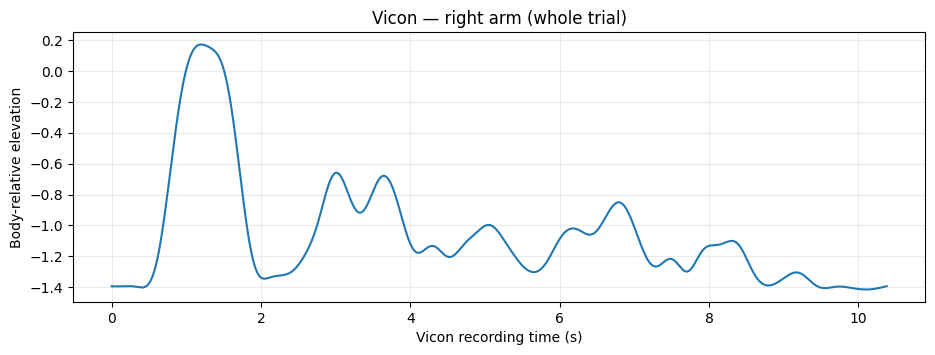

cam0: s11_lunge_cam0_sam_sync.csv — found


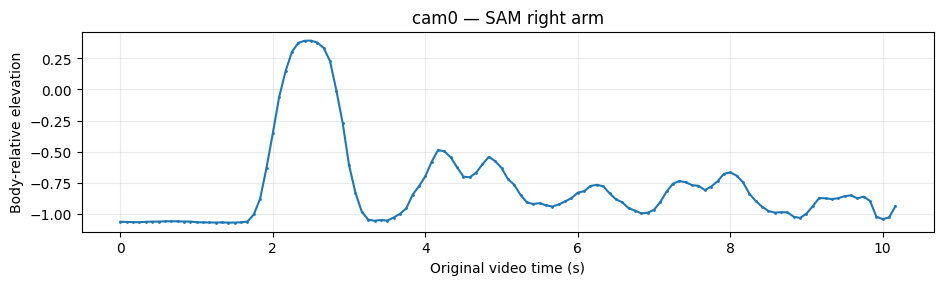

cam1: s11_lunge_cam1_sam_sync.csv — found


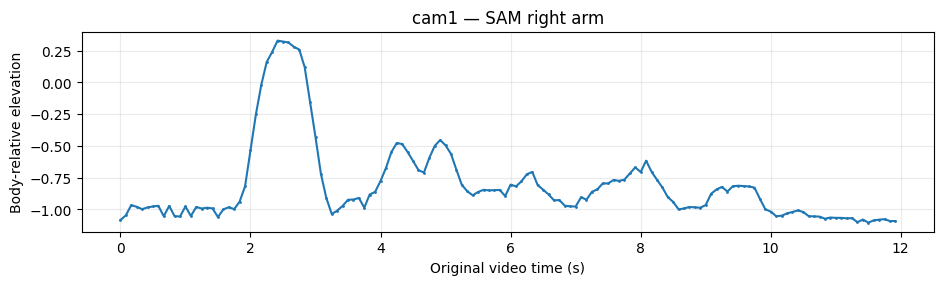

In [45]:
vicon_col = f'{SYNC_ARM}_arm_raise'
fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(vicon_sync['time_ms'] / 1000, vicon_sync[vicon_col])
ax.set(xlabel='Vicon recording time (s)', ylabel='Body-relative elevation', title=f'Vicon — {SYNC_ARM} arm (whole trial)')
ax.grid(alpha=.25)
plt.show()

SAM_INPUTS = {
    camera: DATA_DIR / f'{SUBJECT.lower()}_lunge_{camera}_sam_sync.csv'
    for camera in CAMERAS
}
for camera, path in SAM_INPUTS.items():
    print(f'{camera}: {path.name} — {"found" if path.is_file() else "MISSING"}')
    if path.is_file():
        test = pd.read_csv(path)
        needed = {'ts', f'{SYNC_ARM}_arm_raise'}
        if not needed.issubset(test.columns):
            print('  Missing required columns:', sorted(needed - set(test.columns)))
            continue
        fig, ax = plt.subplots(figsize=(11, 2.6))
        ax.plot(test['ts']/1000, test[f'{SYNC_ARM}_arm_raise'], marker='.', ms=2)
        ax.set(xlabel='Original video time (s)', ylabel='Body-relative elevation', title=f'{camera} — SAM {SYNC_ARM} arm')
        ax.grid(alpha=.25)
        plt.show()


## 3. Batch synchronization across cameras

The existing `synchronize()` detects the largest peak inside `WINDOW_MS` counted separately from the start of each recording. **That is not a robust general event matcher**. Keep `status='review'`; flag weak/ambiguous cases instead of automatically accepting offsets. If a camera lacks the event, skip it pending explicit event-window support in `src/synchronization.py`.


,subject,trial,camera,arm,video_sync_file,method,shift_ms,video_event_ms,vicon_event_ms,video_prominence,vicon_prominence,status,note
0,S11,lunge_01,cam0,right,s11_lunge_cam0_sam_sync.csv,rise50,-1206.427259,2002.026079,795.59882,1.439034,1.568706,review,Confirm event identity visually; no joint-angl...
1,S11,lunge_01,cam1,right,s11_lunge_cam1_sam_sync.csv,rise50,-1263.471162,2059.069982,795.59882,1.301417,1.568706,review,Confirm event identity visually; no joint-angl...


Candidate summary saved: /Users/thomasjohnson/markerless/markerless_sam/results/S11/lunge_01/sync_candidates.csv

Synchronization candidate — cam0


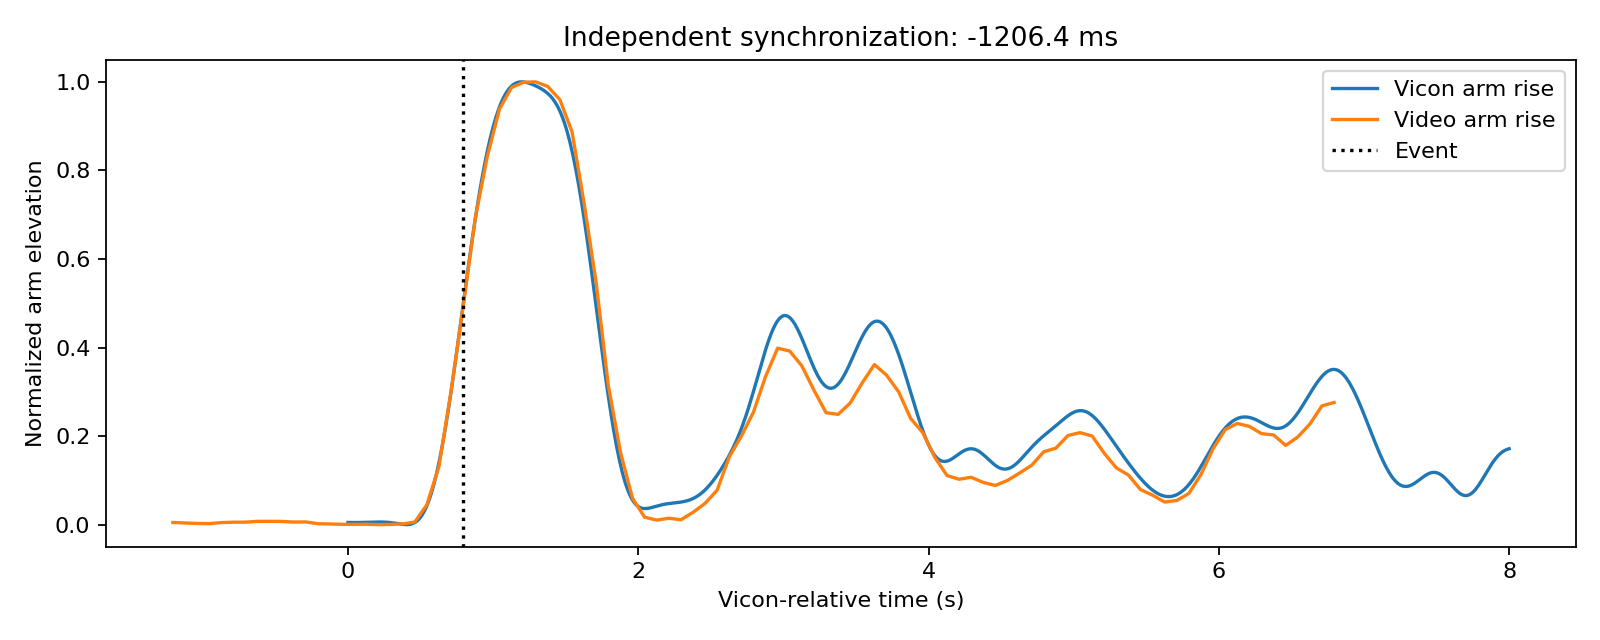


Synchronization candidate — cam1


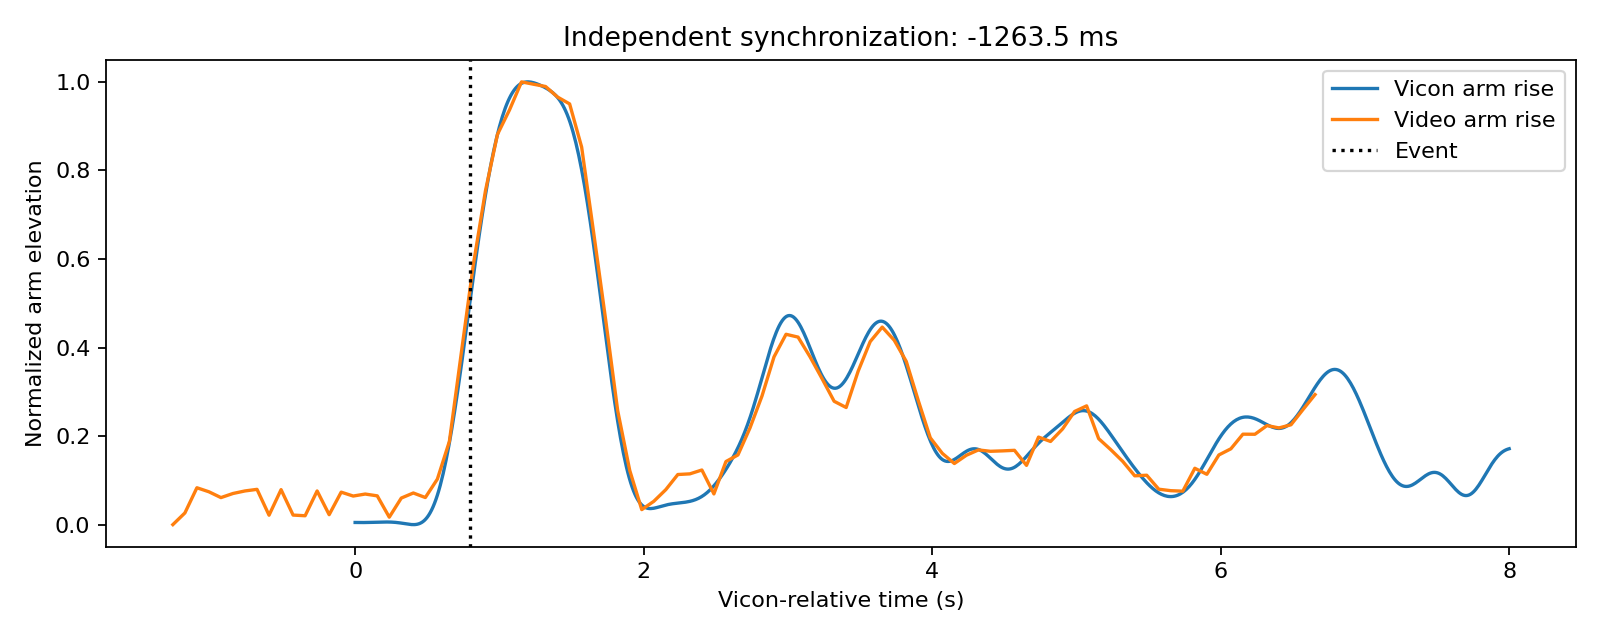

In [46]:

records = []

for camera in CAMERAS:

    video_sync_path = SAM_INPUTS[camera]

    row = {
        "subject": SUBJECT,
        "trial": TRIAL,
        "camera": camera,
        "arm": SYNC_ARM,
        "video_sync_file": video_sync_path.name,
    }

    if not video_sync_path.is_file():
        records.append({
            **row,
            "status": "missing_video_sync",
            "note": str(video_sync_path),
        })
        continue

    out_dir = RESULTS_DIR / SUBJECT / TRIAL / camera

    try:
        result = synchronize(
            video_sync_csv=video_sync_path,
            vicon_sync_csv=VICON_SYNC_PATH,
            video_time_col="ts",
            video_signal_col=f"{SYNC_ARM}_arm_raise",
            vicon_time_col="time_ms",
            vicon_signal_col=f"{SYNC_ARM}_arm_raise",
            method="rise50",
            window_ms=WINDOW_MS,
            output_json=out_dir / "sync_candidate.json",
            output_plot=out_dir / "sync_candidate.png",
        )

        records.append({
            **row,
            **vars(result),
        })

    except (ValueError, KeyError, IndexError) as exc:
        records.append({
            **row,
            "status": "failed",
            "error_type": type(exc).__name__,
            "note": str(exc),
        })

# --------------------------------------------------
# Summary
# --------------------------------------------------

sync_summary = pd.DataFrame(records)

display(sync_summary)

summary_path = (
    RESULTS_DIR / SUBJECT / TRIAL / "sync_candidates.csv"
)

summary_path.parent.mkdir(parents=True, exist_ok=True)
sync_summary.to_csv(summary_path, index=False)

print("Candidate summary saved:", summary_path)

# --------------------------------------------------
# Display plots from THIS run only
# --------------------------------------------------

for _, row in sync_summary.iterrows():

    camera = row["camera"]

    if row["status"] != "review":
        print(f"{camera}: {row['status']} — {row.get('note', '')}")
        continue

    plot_path = (
        RESULTS_DIR / SUBJECT / TRIAL
        / camera / "sync_candidate.png"
    )

    print(f"\nSynchronization candidate — {camera}")
    display(Image(filename=str(plot_path)))

## Quality control / next implementation

- Confirm the SAM CSV, source video and C3D are the **same subject and trial**. Check that C3D relative `time_ms` uses the intended zero origin.
- Visually identify **the same physical arm raise**, selected arm and direction on each system; reject tracking jumps and wrong peaks.
- Look for a second shared event to test clock drift. Cam2 can be left **unverified** while cam0/cam1 progress.
- Compare results with previously aligned joint-angle files only diagnostically; **do not fit the final shift to hip or knee curves**.
- Before final acceptance, improve `src/synchronization.py` to accept *independent* Vicon/video event windows and add an explicit review/acceptance step.
- Apply an **accepted** camera-specific `sync.json` only to a SAM-only angle CSV with original video `time_ms`, never to a CSV already containing `time_ms_aligned`.
